<a href="https://colab.research.google.com/github/uncertain-uncertainity/Learning/blob/main/autistic_patients.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autism Spectrum Disorder Prediction using Machine Learning

Predicting ASD in adults from the AQ-10 screening dataset (about 700 samples) using Logistic Regression, SVM and Random Forest. Data leakage is identified and removed, features are selected with Chi-Square, Mutual Information and RFE, and models are tuned with GridSearchCV and RandomizedSearchCV.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, chi2, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC

RANDOM_STATE = 42

## 1. Data

In [5]:
df = pd.read_csv('/content/autism_screening.csv')
print(df.shape)
df.head()

(704, 21)


,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,...,gender,ethnicity,jundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,1,1,0,0,1,1,0,0,...,f,White-European,no,no,United States,no,6,18 and more,Self,NO
1,1,1,0,1,0,0,0,1,0,1,...,m,Latino,no,yes,Brazil,no,5,18 and more,Self,NO
2,1,1,0,1,1,0,1,1,1,1,...,m,Latino,yes,yes,Spain,no,8,18 and more,Parent,YES
3,1,1,0,1,0,0,1,1,0,1,...,f,White-European,no,yes,United States,no,6,18 and more,Self,NO
4,1,0,0,0,0,0,0,1,0,0,...,f,?,no,no,Egypt,no,2,18 and more,?,NO


In [6]:
df.isin(['?']).sum()[lambda s: s > 0]

,0
age,2
ethnicity,95
relation,95


## 2. Cleaning

`age` contains `?` entries and one impossible value, ethnicity has `?` and inconsistent labels, `age_desc` has a single value and `relation` records who filled in the form, so both are dropped.

In [7]:
df['ethnicity'] = df['ethnicity'].str.strip().replace({'?': 'Others', 'others': 'Others'})
df['contry_of_res'] = df['contry_of_res'].str.strip()
df = df.drop(columns=['age_desc', 'relation'])
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df = df.dropna(subset=['age'])
df = df[df['age'] < 100].reset_index(drop=True)
df['Class/ASD'] = df['Class/ASD'].map({'YES': 1, 'NO': 0})

a_cols = [f'A{i}_Score' for i in range(1, 11)]
print(df.shape)
df['Class/ASD'].value_counts(normalize=True).round(3)

(701, 19)


,proportion
Class/ASD,
0,0.73
1,0.27


## 3. Exploratory analysis

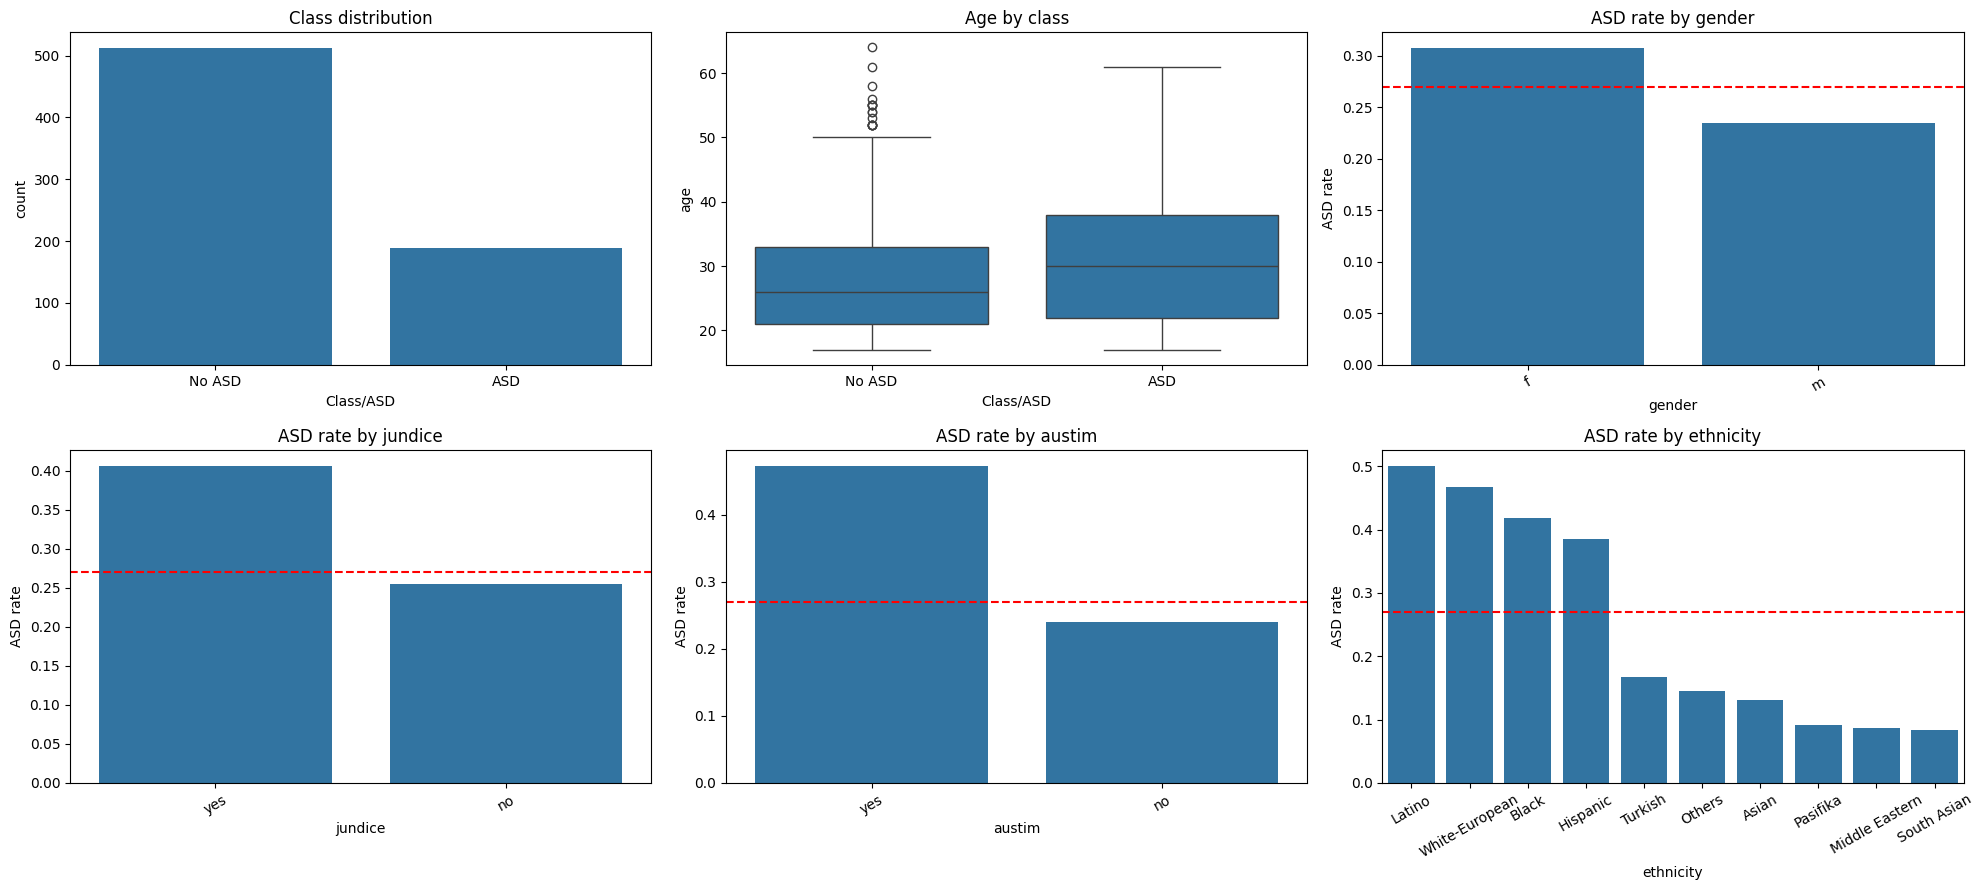

In [8]:
label = df['Class/ASD'].map({0: 'No ASD', 1: 'ASD'})
fig, axes = plt.subplots(2, 3, figsize=(20, 9))

sns.countplot(x=label, ax=axes[0, 0])
axes[0, 0].set_title('Class distribution')

sns.boxplot(x=label, y=df['age'], ax=axes[0, 1])
axes[0, 1].set_title('Age by class')

for ax, col in zip([axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]],
                   ['gender', 'jundice', 'austim', 'ethnicity']):
    rate = df.groupby(col)['Class/ASD'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(df['Class/ASD'].mean(), color='red', linestyle='--')
    ax.set_title(f'ASD rate by {col}')
    ax.set_ylabel('ASD rate')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 4. Data leakage

`result` is the AQ-10 total score and equals the sum of `A1_Score` to `A10_Score`. The cell below checks how the label `Class/ASD` relates to it. If the label is a direct function of these columns, any model given `result` or the ten item scores can reconstruct the answer instead of predicting it, so these columns are removed. The comparison shows cross-validated ROC-AUC for Logistic Regression before and after the fix.

In [9]:
print('result equals sum of A1-A10:', (df['result'] == df[a_cols].sum(axis=1)).all())
print('Class/ASD equals (result >= 7):', ((df['result'] >= 7).astype(int) == df['Class/ASD']).all())
pd.crosstab(df['result'], df['Class/ASD'])

result equals sum of A1-A10: True
Class/ASD equals (result >= 7): True


Class/ASD,0,1
result,,
0,13,0
1,32,0
2,74,0
3,110,0
4,130,0
5,83,0
6,70,0
7,0,57
8,0,55


In [10]:
cat_cols = ['gender', 'ethnicity', 'jundice', 'austim', 'contry_of_res', 'used_app_before']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def logreg():
    return LogisticRegression(max_iter=1000, class_weight='balanced')


feature_sets = {
    'With result': (['age', 'result'], []),
    'With A1-A10 (result removed)': (['age'], a_cols),
    'Leakage-free (result and A1-A10 removed)': (['age'], []),
}

rows = []
for name, (num, binary) in feature_sets.items():
    pipe = Pipeline([
        ('prep', ColumnTransformer([
            ('num', MinMaxScaler(), num),
            ('bin', 'passthrough', binary),
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ], sparse_threshold=0)),
        ('clf', logreg()),
    ])
    auc = cross_val_score(pipe, df[num + binary + cat_cols], df['Class/ASD'], cv=cv, scoring='roc_auc')
    rows.append({'Feature set': name, 'CV ROC-AUC': round(auc.mean(), 4)})

pd.DataFrame(rows).set_index('Feature set')

,CV ROC-AUC
Feature set,
With result,0.9970
With A1-A10 (result removed),0.9998
Leakage-free (result and A1-A10 removed),0.7469


The train/test split is made before any scaling, encoding or feature selection, and these steps are fitted inside a pipeline on training folds only. The remaining features are `age`, `gender`, `ethnicity`, `jundice`, `austim`, `contry_of_res` and `used_app_before`.

In [11]:
X = df[['age'] + cat_cols]
y = df['Class/ASD']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)

preprocessor = ColumnTransformer([
    ('age', MinMaxScaler(), ['age']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
], sparse_threshold=0)

(560, 7) (141, 7)


## 5. Feature selection

Chi-Square, Mutual Information and RFE (with Logistic Regression) are applied to the preprocessed training data and the top 15 features from each are compared. Each method is then cross-validated with Logistic Regression against a no-selection baseline.

In [12]:
def mi_score(X, y):
    discrete = np.ones(X.shape[1], dtype=bool)
    discrete[0] = False
    return mutual_info_classif(X, y, discrete_features=discrete, random_state=RANDOM_STATE)


K = 15
X_train_pre = preprocessor.fit_transform(X_train)
feature_names = np.array([n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()])

chi2_scores, _ = chi2(X_train_pre, y_train)
mi_scores = mi_score(X_train_pre, y_train)
rfe = RFE(logreg(), n_features_to_select=K, step=5).fit(X_train_pre, y_train)

top_features = pd.DataFrame({
    'Chi-Square': feature_names[np.argsort(chi2_scores)[::-1][:K]],
    'Mutual Information': feature_names[np.argsort(mi_scores)[::-1][:K]],
    'RFE': feature_names[rfe.support_],
})
print('Total features after encoding:', len(feature_names))
top_features

Total features after encoding: 81


,Chi-Square,Mutual Information,RFE
0,ethnicity_White-European,ethnicity_White-European,ethnicity_Latino
1,contry_of_res_United States,contry_of_res_United Arab Emirates,ethnicity_White-European
2,contry_of_res_United Arab Emirates,contry_of_res_United States,contry_of_res_Austria
3,austim_yes,contry_of_res_India,contry_of_res_Brazil
4,contry_of_res_India,ethnicity_Middle Eastern,contry_of_res_Canada
5,ethnicity_Middle Eastern,contry_of_res_Jordan,contry_of_res_China
6,contry_of_res_Jordan,austim_no,contry_of_res_France
7,ethnicity_Asian,austim_yes,contry_of_res_India
8,jundice_yes,age,contry_of_res_Iran
9,ethnicity_Others,ethnicity_Asian,contry_of_res_Italy


In [13]:
selectors = {
    'None': 'passthrough',
    'Chi-Square': SelectKBest(chi2, k=K),
    'Mutual Information': SelectKBest(mi_score, k=K),
    'RFE': RFE(logreg(), n_features_to_select=K, step=5),
}

rows = []
for name, selector in selectors.items():
    pipe = Pipeline([('prep', preprocessor), ('selector', selector), ('clf', logreg())])
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    rows.append({
        'Selection': name,
        'Features': len(feature_names) if name == 'None' else K,
        'CV ROC-AUC': round(auc.mean(), 4),
    })

pd.DataFrame(rows)

,Selection,Features,CV ROC-AUC
0,None,81,0.7456
1,Chi-Square,15,0.7449
2,Mutual Information,15,0.7461
3,RFE,15,0.7253


## 6. Hyperparameter tuning

The feature selector and its size are tuned together with the classifier inside one pipeline. GridSearchCV is used for Logistic Regression and SVM, and RandomizedSearchCV for the larger Random Forest and Extra Trees search spaces. All searches optimise ROC-AUC with 5-fold stratified cross-validation on the training set.

In [14]:
def make_pipeline(clf):
    return Pipeline([('prep', preprocessor), ('selector', 'passthrough'), ('clf', clf)])


def build_space(clf_params, sizes=(10, 20, 30, 40)):
    sizes = list(sizes)
    selector_space = [
        {'selector': [SelectKBest(chi2)], 'selector__k': sizes},
        {'selector': [SelectKBest(mi_score)], 'selector__k': sizes},
        {'selector': [RFE(logreg(), step=5)], 'selector__n_features_to_select': sizes},
    ]
    return [{**s, **clf_params} for s in selector_space]


tree_params = {
    'clf__n_estimators': randint(100, 500),
    'clf__max_depth': [None, 3, 5, 8],
    'clf__min_samples_leaf': randint(1, 8),
    'clf__max_features': ['sqrt', 'log2', 0.5],
}

searches = {
    'Logistic Regression': GridSearchCV(
        make_pipeline(logreg()),
        build_space({'clf__C': [0.01, 0.1, 1, 10, 100]}),
        scoring='roc_auc', cv=cv, n_jobs=-1),
    'SVM': GridSearchCV(
        make_pipeline(SVC(class_weight='balanced')),
        build_space({'clf__C': [0.1, 1, 10],
                     'clf__kernel': ['linear', 'rbf'],
                     'clf__gamma': ['scale', 0.01]}),
        scoring='roc_auc', cv=cv, n_jobs=-1),
    'Random Forest': RandomizedSearchCV(
        make_pipeline(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
        build_space(tree_params),
        n_iter=40, scoring='roc_auc', cv=cv, n_jobs=-1, random_state=RANDOM_STATE),
    'Extra Trees': RandomizedSearchCV(
        make_pipeline(ExtraTreesClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
        build_space(tree_params),
        n_iter=40, scoring='roc_auc', cv=cv, n_jobs=-1, random_state=RANDOM_STATE),
}

In [15]:
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f'{name} | best CV ROC-AUC: {search.best_score_:.4f}')
    print(search.best_params_, '\n')

Logistic Regression | best CV ROC-AUC: 0.7595
{'clf__C': 0.01, 'selector': RFE(estimator=LogisticRegression(class_weight='balanced', max_iter=1000),
    step=5), 'selector__n_features_to_select': 30} 

SVM | best CV ROC-AUC: 0.7588
{'clf__C': 1, 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'selector': RFE(estimator=LogisticRegression(class_weight='balanced', max_iter=1000),
    step=5), 'selector__n_features_to_select': 30} 

Random Forest | best CV ROC-AUC: 0.7564
{'clf__max_depth': 8, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 7, 'clf__n_estimators': 206, 'selector': RFE(estimator=LogisticRegression(class_weight='balanced', max_iter=1000),
    step=5), 'selector__n_features_to_select': 40} 

Extra Trees | best CV ROC-AUC: 0.7495
{'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 4, 'clf__n_estimators': 149, 'selector': RFE(estimator=LogisticRegression(class_weight='balanced', max_iter=1000),
    step=5), 'selector__n_features_to_select': 40} 



## 7. Evaluation

Tuned models are evaluated once on the held-out test set using precision, recall, F1-score and ROC-AUC. ROC-AUC is computed from predicted probabilities (decision scores for SVM) rather than hard labels. The test set is small, so cross-validated ROC-AUC from the training set is shown next to it.

In [16]:
def predict_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


rows, roc_curves = [], {}
for name, search in searches.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    y_score = predict_scores(model, X_test)
    roc_curves[name] = roc_curve(y_test, y_score)
    rows.append({
        'Model': name,
        'CV ROC-AUC': search.best_score_,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_score),
    })

results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('CV ROC-AUC', ascending=False)
results

,CV ROC-AUC,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7595,0.4773,0.5526,0.5122,0.7164
SVM,0.7588,0.4737,0.4737,0.4737,0.7121
Random Forest,0.7564,0.4815,0.6842,0.5652,0.7234
Extra Trees,0.7495,0.4694,0.6053,0.5287,0.7303


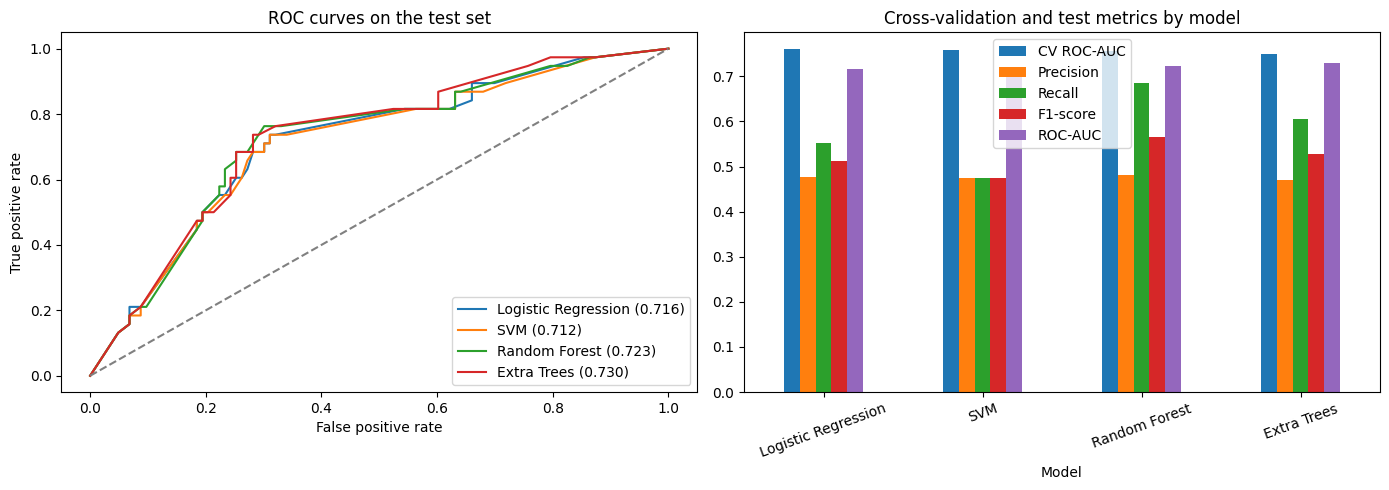

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, (fpr, tpr, _) in roc_curves.items():
    axes[0].plot(fpr, tpr, label=f"{name} ({results.loc[name, 'ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curves on the test set')
axes[0].legend()

results[['CV ROC-AUC', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']].plot(kind='bar', ax=axes[1])
axes[1].set_title('Cross-validation and test metrics by model')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

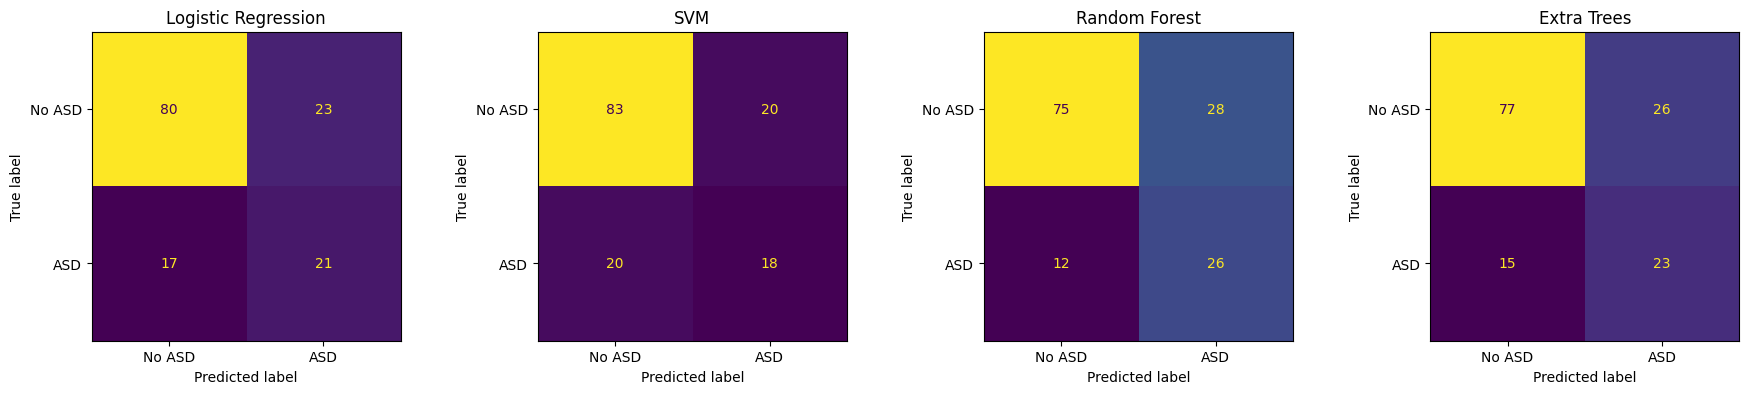

In [18]:
fig, axes = plt.subplots(1, len(searches), figsize=(18, 4))
for ax, (name, search) in zip(axes, searches.items()):
    ConfusionMatrixDisplay.from_estimator(
        search.best_estimator_, X_test, y_test,
        display_labels=['No ASD', 'ASD'], colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [19]:
def selector_label(selector):
    if isinstance(selector, RFE):
        return 'RFE'
    return 'Chi-Square' if selector.score_func is chi2 else 'Mutual Information'


rows = []
for name, search in searches.items():
    model = search.best_estimator_
    selector = model.named_steps['selector']
    selected = model.named_steps['prep'].get_feature_names_out()[selector.get_support()]
    rows.append({
        'Model': name,
        'Selection method': selector_label(selector),
        'Features kept': len(selected),
    })

pd.DataFrame(rows).set_index('Model')

,Selection method,Features kept
Model,,
Logistic Regression,RFE,30
SVM,RFE,30
Random Forest,RFE,40
Extra Trees,RFE,40


In [20]:
print(f"Highest CV ROC-AUC: {results['CV ROC-AUC'].idxmax()} ({results['CV ROC-AUC'].max():.4f})")
print(f"Highest test ROC-AUC: {results['ROC-AUC'].idxmax()} ({results['ROC-AUC'].max():.4f})")
print(f"Samples used: {len(df)} (train {len(X_train)}, test {len(X_test)})")

Highest CV ROC-AUC: Logistic Regression (0.7595)
Highest test ROC-AUC: Extra Trees (0.7303)
Samples used: 701 (train 560, test 141)
